# 02 · Loading and chunking, by hand

Notebook 01 started from eight tidy passages. Real documents are PDFs with tables, Markdown with
headers, HTML with navigation bars, and spreadsheets. Before we can retrieve anything we have to
**load** them into text and **chunk** them into retrieval-sized pieces.

**In this notebook you will:**
- write loaders for PDF, Markdown, HTML and CSV, and look at the messy text they produce,
- compare three chunking strategies: fixed-size, recursive and header-aware,
- see why chunks overlap,
- attach metadata to chunks, and see how a short "context prefix" helps retrieval.

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT.name if ROOT else '?'} | chat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: RAG-lab | chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: nothing to prepare. Everything here runs locally on the files in data/corpus.

In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

## 1. Loading: every format is messy in its own way

A loader turns a file into one or more **Documents**: `page_content` (text) plus `metadata`
(where it came from). `raglab.loaders` has one small function per format. We borrow LangChain's
`Document` class only as a container; it's a plain data class.

In [4]:
from raglab import loaders

corpus = settings.corpus_dir
pdf_pages = loaders.load_pdf(corpus / "hotel_profiles.pdf")
print(f"{len(pdf_pages)} pages")
print(pdf_pages[1].metadata)
print(pdf_pages[1].page_content[:900])

4 pages
{'source_file': 'hotel_profiles.pdf', 'page': 2}
Token Vancouver
Token Vancouver is a glass tower in Coal Harbour with views of the North Shore mountains. It is popular with
business travellers and with families heading to Stanley Park.
Check-in at Token Vancouver starts at 3:30 PM and check-out is at 12:00 PM. The hotel has 210 rooms, and rates
at Token Vancouver start from $310 per night. Guests can use an indoor saltwater pool. The hotel also has a
full-service spa with six treatment rooms. The Canada Line SkyTrain station is two blocks away; the hotel does not
run a shuttle.
Feature Token Vancouver
Location Vancouver, Canada (North America)
Star rating 4 stars
Rooms 210
Swimming pool Yes
Spa Yes
Check-in / check-out 3:30 PM / 12:00 PM
Rates from $310 per night
Restaurants Tidewater Grill
Token Queenstown
Token Queenstown is a timber-and-stone lodge on the edge of Lake Wakatipu. Guests use it as a base for skiing
in winter and hikin


**PDF:** text comes out page by page, and the line breaks are wherever the PDF wrapped the line,
not where sentences end. The amenities **table** is flattened into lines like
`Swimming pool Yes`; the column structure is gone. A page also holds more than one hotel.

In [5]:
faq = loaders.load_html(corpus / "faq.html")[0]
print(faq.page_content[:400])

Home
·
Hotels
·
Offers
·
Sign in
Token Hotels & Resorts — Frequently Asked Questions
Answers to the questions our front desks hear most. For anything else, contact the hotel directly.
Reservations and check-in
Can I check in early?
Early check-in depends on availability on the day. To guarantee a room from 9:00 AM, book the Early Arrival add-on for $50.
Can I check out late?
Late checkout until 2:


**HTML:** we dropped scripts and styles, but the navigation bar (`Home · Hotels · Offers`) and the
footer are still there. Boilerplate like this ends up in chunks and in search results unless you
remove it. We keep the raw HTML in `metadata["raw_html"]` because its `<h1>`/`<h2>` structure
is useful for chunking (notebook 04).

In [6]:
rates = loaders.load_csv(corpus / "room_rates.csv")
print(f"{len(rates)} rows; first row as a document:\n{rates[0].page_content}")

48 rows; first row as a document:
hotel: Token Lisbon
city: Lisbon
room_type: Standard
season: low
nightly_rate_usd: 240
max_guests: 2


**CSV:** each row becomes a tiny document. That works for lookups ("Suite at Token Kyoto in high
season?") but it's a poor fit for questions like "cheapest suite in Asia?", which need arithmetic
across rows. Notebook 12 gives that job to a proper tool instead.

`load_corpus()` loads every file in one go:

In [7]:
docs = loaders.load_corpus()
import collections

collections.Counter(d.metadata["source_file"] for d in docs)

Counter({'room_rates.csv': 48,
         'hotel_profiles.pdf': 4,
         'cancellation_policy_2024.md': 1,
         'cancellation_policy_2025.md': 1,
         'dining_guide.md': 1,
         'faq.html': 1,
         'guest_reviews.md': 1,
         'loyalty_program.md': 1,
         'loyalty_program_reprint.md': 1})

A quick sanity check worth doing on any new corpus: did accented characters survive? (Text files
must be read as UTF-8; PDF extraction depends on the PDF's fonts.)

In [8]:
for d in docs:
    line = next((ln for ln in d.page_content.splitlines() if "Reykjav" in ln), None)
    if line:
        print(f"{d.metadata['source_file']:<28}{line.strip()[:70]}")

dining_guide.md             ## Token Reykjavík
faq.html                    Token Vancouver and Token Singapore offer valet parking for $45 per ni
guest_reviews.md            ## Token Reykjavík
hotel_profiles.pdf          Token Reykjavík
room_rates.csv              hotel: Token Reykjavík
room_rates.csv              hotel: Token Reykjavík
room_rates.csv              hotel: Token Reykjavík
room_rates.csv              hotel: Token Reykjavík
room_rates.csv              hotel: Token Reykjavík
room_rates.csv              hotel: Token Reykjavík


## 2. Why chunk at all?

One embedding per *document* would squeeze a whole dining guide (eight restaurants) into a
single vector. A question about one restaurant would then be compared against an average of all
eight. Smaller chunks give sharper vectors, and they keep the prompt short.

But chunks that are *too* small lose context ("It opens at 7 PM." Which restaurant?). Chunking
is a trade-off, and the strategy matters.

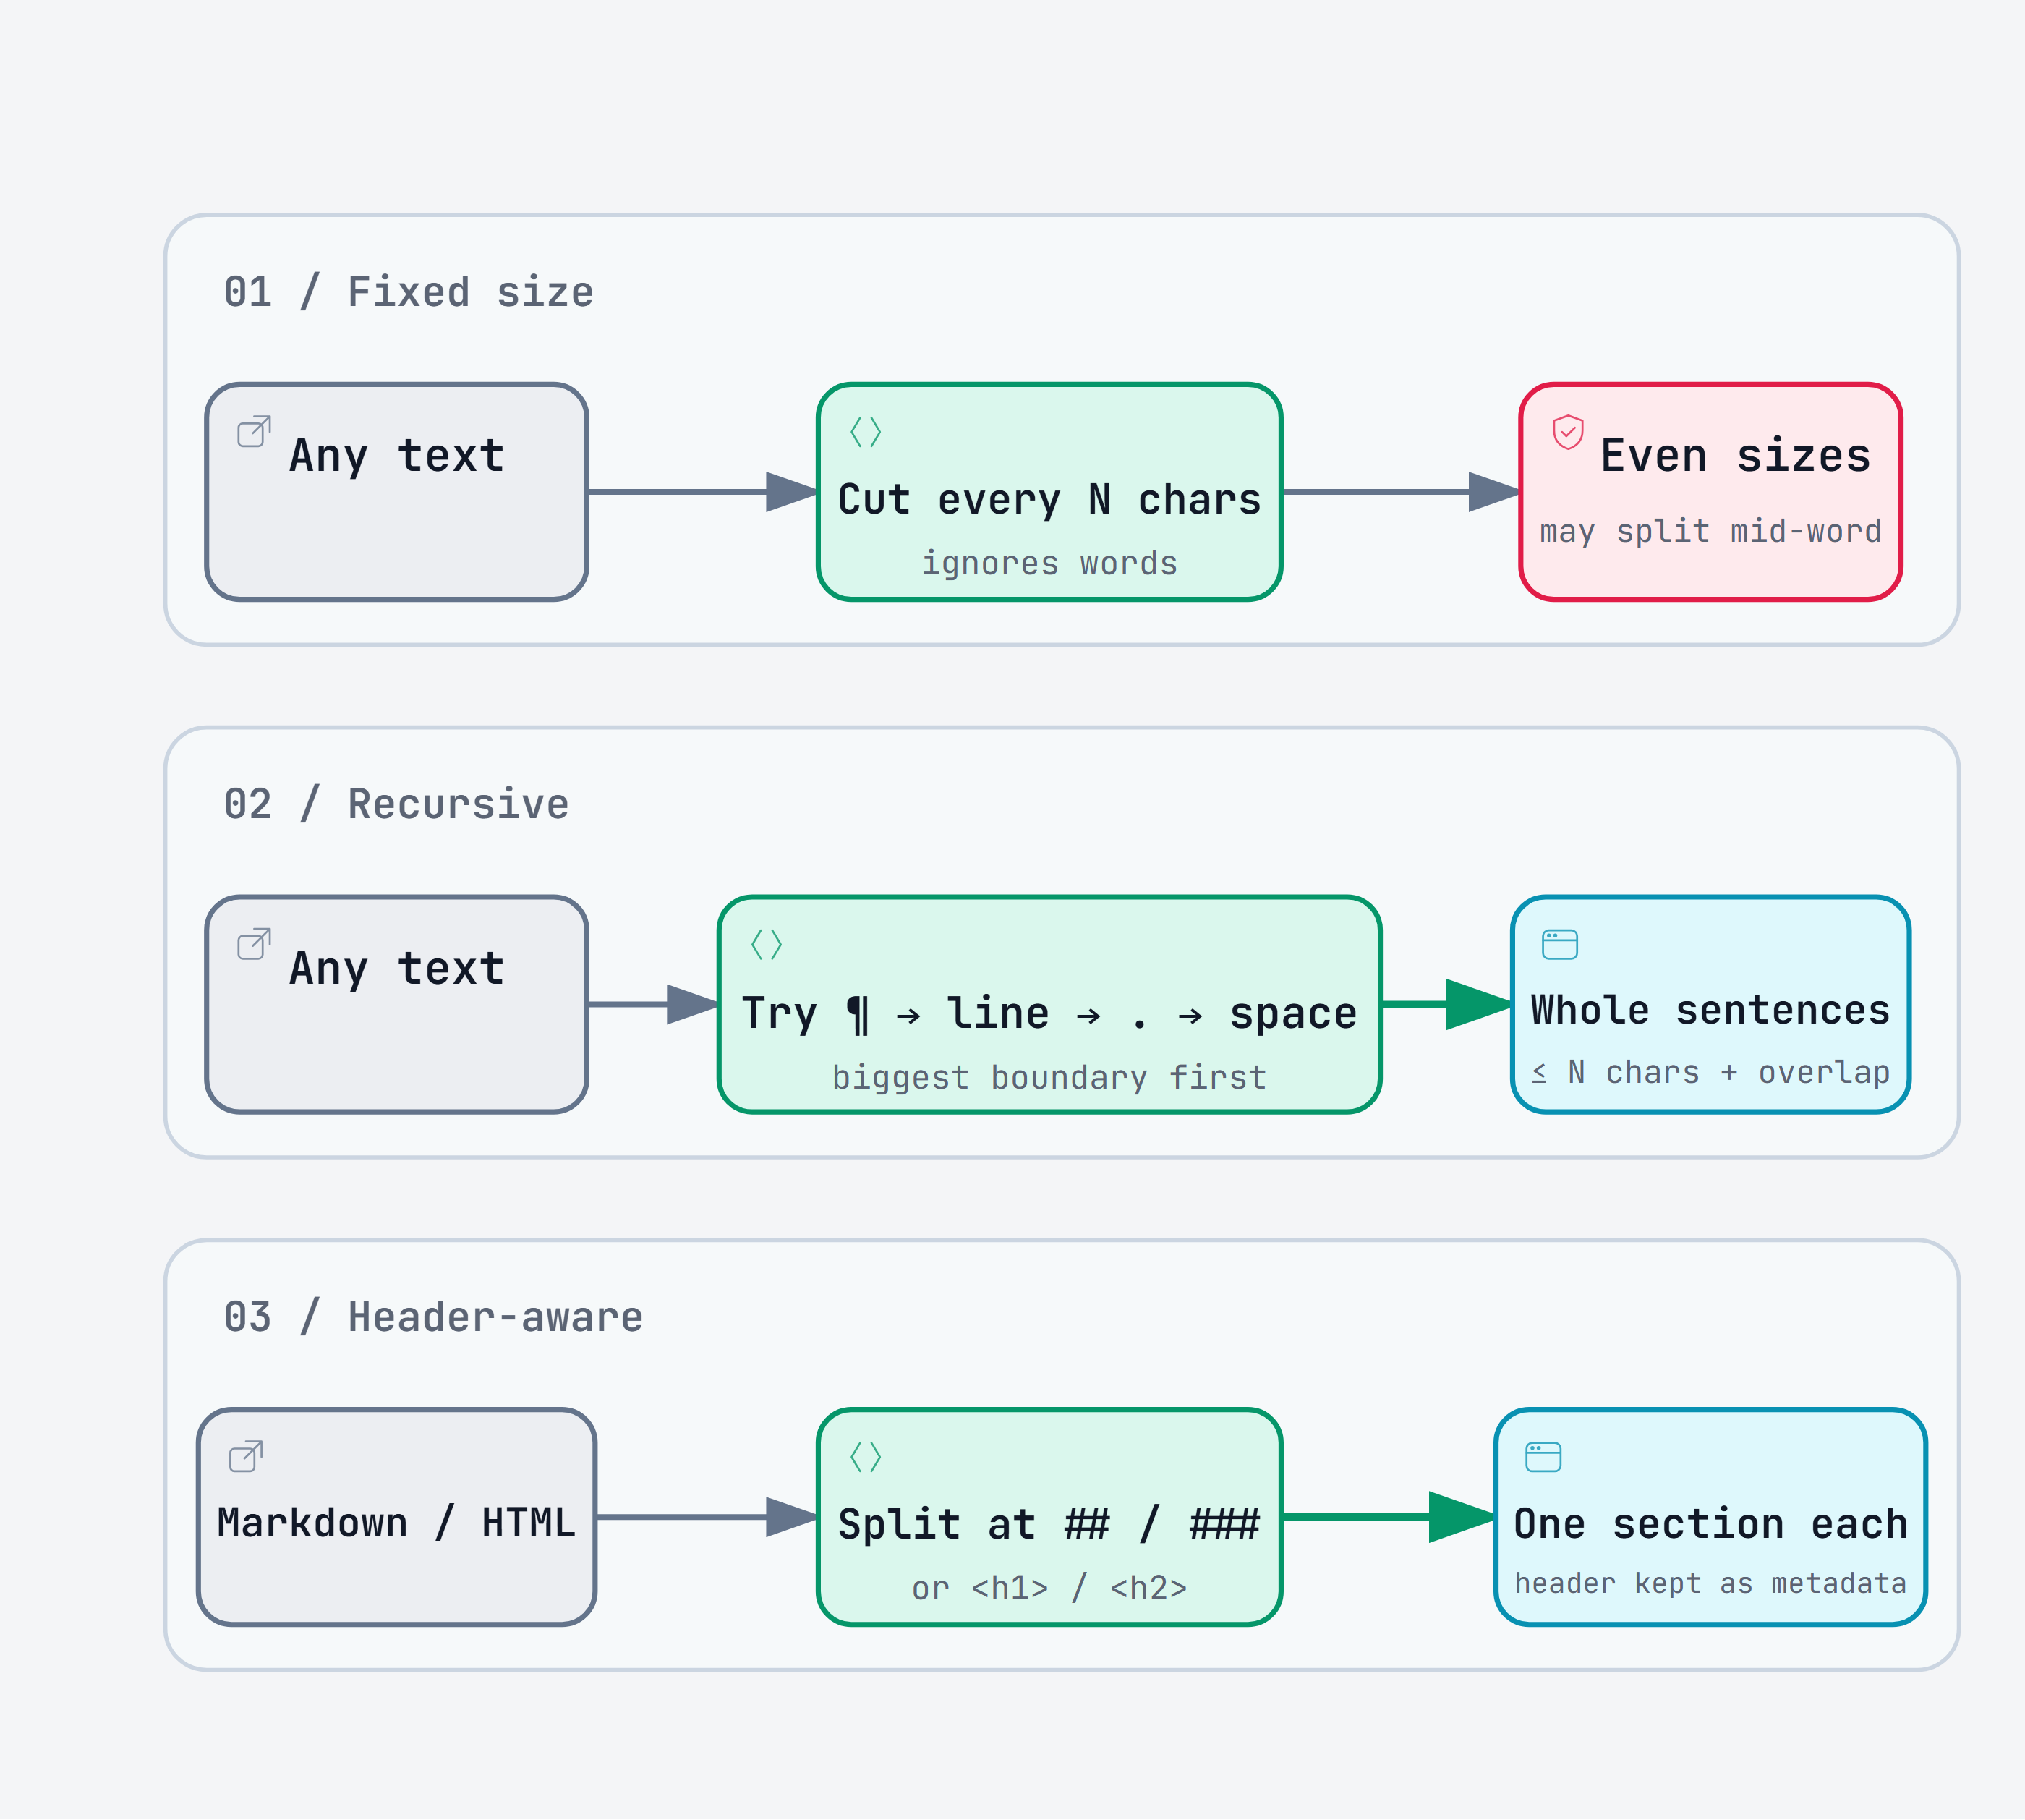

[Open interactive version](../diagrams/chunking_strategies.html)

In [9]:
from raglab.display import show_diagram

show_diagram("chunking_strategies")

We'll compare the three strategies on the Markdown dining guide.

In [10]:
from raglab import chunking

dining = loaders.load_markdown(corpus / "dining_guide.md")
fixed = chunking.chunk_fixed(dining, size=500)
recursive = chunking.chunk_recursive(dining, size=500, overlap=100)
by_header = chunking.chunk_markdown_headers(dining)
print(f"fixed: {len(fixed)} chunks | recursive: {len(recursive)} | header-aware: {len(by_header)}")

fixed: 9 chunks | recursive: 10 | header-aware: 10


### Fixed-size: cut every N characters

Look at where the first chunk ends and the second begins:

In [11]:
print(repr(fixed[0].page_content[-120:]))
print(repr(fixed[1].page_content[:120]))

' closed Sundays\n- **Dress code:** Smart casual\n- **Reservations:** Recommended\n\nChef Inês Carvalho grew up in a fishing '
'family in Peniche and buys her fish at the Cascais market every morning. The signature dish at Maré is the cataplana of '


The cut lands wherever character 500 falls, often mid-word or mid-sentence, so a fact can be
split across two chunks and neither chunk contains it whole.

### Recursive: split at natural boundaries

`chunk_recursive` tries the biggest boundary first (blank line), then a line break, then a
sentence end (`". "`), then a space. Only pieces still too long are split further. Then it packs
the pieces back together up to `size` characters.

In [12]:
for chunk in recursive[:2]:
    print(repr(chunk.page_content[:160]), "…", repr(chunk.page_content[-80:]), "\n")

'# Token Hotels & Resorts — Dining Guide\n\nEvery Token Hotels & Resorts property has at least one restaurant run by a chef from the region. Menus change with the ' … 'M, closed Sundays\n- **Dress code:** Smart casual\n- **Reservations:** Recommended' 

'Chef Inês Carvalho grew up in a fishing family in Peniche and buys her fish at the Cascais market every morning. The signature dish at Maré is the cataplana of ' … '* Smart; no shorts or sandals\n- **Reservations:** Required at least 3 days ahead' 



Chunks now start and end at line or paragraph boundaries.

### Header-aware: one section per chunk

Markdown already tells us where topics change: the headers. `chunk_markdown_headers` starts a new
chunk at every `##` and `###`, keeps the header in the text, and records the header path in metadata.

In [13]:
from raglab.display import show_chunks

show_chunks(by_header, n=2, width=250)

10 chunk(s), showing 2

[1] source_file=dining_guide.md  (244 chars)
    # Token Hotels & Resorts — Dining Guide Every Token Hotels & Resorts property has at least one
    restaurant run by a chef from the region. Menus change with the seasons, and hotel guests can book
    any restaurant through the front desk or the app.

[2] source_file=dining_guide.md | section=Token Lisbon | subsection=Maré — Token Lisbon  (443 chars)
    ### Maré — Token Lisbon - **Cuisine:** Portuguese seafood - **Chef:** Inês Carvalho - **Hours:**
    7:00 PM - 11:00 PM, closed Sundays - **Dress code:** Smart casual - **Reservations:** Recommended
    Chef Inês Carvalho grew up in a fishing family in Pen …


Each chunk is exactly one restaurant, and `section` / `subsection` say which hotel it belongs to.

### Chunk sizes compared

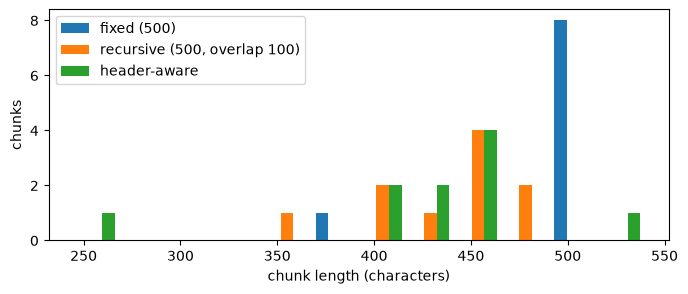

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(
    [[len(c.page_content) for c in s] for s in (fixed, recursive, by_header)],
    bins=12,
    label=["fixed (500)", "recursive (500, overlap 100)", "header-aware"],
)
ax.set_xlabel("chunk length (characters)")
ax.set_ylabel("chunks")
ax.legend()
plt.show()

Fixed chunks are all the same size by construction. Header-aware chunks follow the content:
one per restaurant, of whatever length that restaurant's entry happens to be. On a document with a
very long section you'd combine both: split by headers first, then split any oversized section recursively.

## 3. Overlap: don't lose facts at the seams

With overlap, the start of each chunk repeats the end of the previous one, so a sentence near a
boundary appears whole in at least one chunk. Let's chunk the first PDF page with
`size=500, overlap=150`:

In [15]:
pdf_chunks = chunking.chunk_recursive(pdf_pages[:1], size=500, overlap=150)
first, second = pdf_chunks[0].page_content, pdf_chunks[1].page_content
shared = next(
    (second[:n] for n in range(min(len(first), len(second)), 0, -1) if first.endswith(second[:n])), ""
)
print(f"{len(shared)} characters shared between chunk 1 and chunk 2:")
print(repr(shared))

130 characters shared between chunk 1 and chunk 2:
'Token Lisbon\nToken Lisbon sits on a cobbled street in the Chiado district, a short walk from the river. The building is a restored'


Our recursive chunker (like LangChain's) carries over **whole pieces**: here, whole lines of the
PDF. If the pieces are bigger than the overlap budget, nothing is carried. Check
`recursive[0]` and `recursive[1]` from the dining guide: its pieces are paragraphs longer than
100 characters, so those chunks share nothing. Overlap is a *maximum*, not a guarantee.

Overlap costs a little storage and some duplicate text in prompts. A common starting point is
10–20% of the chunk size.

## 4. Metadata: what is this chunk about?

`enrich_metadata` adds a `doc_type` (from the file name) and, when a chunk is about exactly one
hotel, that hotel's facts: city, continent, stars, price, pool, spa. Later notebooks filter on
these fields ("hotels in Asia with a pool").

Let's split the header chunks further into small pieces, like you might for a long document:

In [16]:
small = chunking.enrich_metadata(chunking.chunk_recursive(by_header, size=250, overlap=50))
orphans = [c for c in small if c.metadata.get("hotel_name") and c.metadata["hotel_name"] not in c.page_content]
print(f"{len(small)} small chunks; {len(orphans)} of them never mention their hotel in the text")
show_chunks(orphans, n=1, width=300)

21 small chunks; 11 of them never mention their hotel in the text
11 chunk(s), showing 1

[1] source_file=dining_guide.md | doc_type=dining | hotel_name=Token Lisbon | section=Token Lisbon | subsection=Maré — Token Lisbon  (246 chars)
    Chef Inês Carvalho grew up in a fishing family in Peniche and buys her fish at the Cascais market
    every morning. The signature dish at Maré is the cataplana of clams and chorizo. At Maré the tasting
    menu costs $95 per person, drinks not included.


That chunk is about one hotel's restaurant, but its text never says which hotel; only the
header metadata knows. A question such as "What is the signature dish at Token Lisbon?" has
nothing to match on.

**Context prefix:** `add_context_prefix` prepends `"<hotel> — <doc type>"` to such chunks before
they are embedded. Let's measure the effect with the similarity we built in notebook 01:

In [17]:
from raglab import llm, scratch

orphan = orphans[0]
with_prefix = chunking.add_context_prefix([orphan])[0]
question = f"What is the signature dish at {orphan.metadata['hotel_name']}?"
vectors = llm.embed([orphan.page_content, with_prefix.page_content])
q = llm.embed_one(question)
plain_score, prefixed_score = scratch.cosine_sim(q, vectors)
print(question)
print(f"similarity without prefix: {plain_score:.3f}")
print(f"similarity with prefix:    {prefixed_score:.3f}")
print("\nprefixed chunk starts with:", repr(with_prefix.page_content[:60]))

What is the signature dish at Token Lisbon?
similarity without prefix: 0.474
similarity with prefix:    0.632

prefixed chunk starts with: 'Token Lisbon — dining\n\nChef Inês Carvalho grew up in a fishi'


A few words of context move the chunk closer to the questions it should answer. Notebook 04
applies this prefix to every chunk in the index.

## Your turn

1. Run `chunk_fixed(dining, size=200)` and find a chunk that cuts a restaurant's hours or price
   in half. What question would now be impossible to answer from a single chunk?
2. Chunk the PDF pages with `chunk_recursive(pdf_pages, 800, 150)` and run `enrich_metadata`.
   How many chunks get a `hotel_name`? Why do the others not get one?
3. Try `chunk_markdown_headers(dining, levels=(2,))`. How many chunks do you get now, and what's in them?

<details><summary>Hints</summary>

2. A PDF page holds two hotels, so an 800-character chunk often straddles both. `enrich_metadata`
   only assigns a hotel when exactly one is named. Structure-aware splitting (or smaller chunks)
   fixes this, at the cost of more chunks.
3. Splitting only at `##` gives one chunk per *hotel* (each containing all of its restaurants),
   a middle ground between the two strategies.
</details>

## Key takeaways

- Loaders produce imperfect text: PDF tables flatten, HTML carries boilerplate, CSV rows lack context.
- Recursive chunking respects sentences; header-aware chunking respects topics. Overlap protects seams.
- Metadata (doc type, hotel, city…) enables filtering, and a context prefix makes small chunks findable.

**Added to raglab:** `loaders.load_pdf / load_markdown / load_html / load_csv / load_corpus`,
`chunking.chunk_fixed / chunk_recursive / chunk_markdown_headers / enrich_metadata / add_context_prefix`.

In [18]:
cost.report()

Cost: no API calls in this notebook ($0.0000)
